<p>Load preprocessed dataset</p>

In [7]:
import os
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
import keras
from keras import layers, models

# Path to pre-processed data
SAVE_DIR = "/home/darren/Desktop/final_project/processed_data"

# Load the saved arrays
X_train = np.load(os.path.join(SAVE_DIR, 'X_train.npy'))
y_train = np.load(os.path.join(SAVE_DIR, 'y_train.npy'))
X_val = np.load(os.path.join(SAVE_DIR, 'X_val.npy'))
y_val = np.load(os.path.join(SAVE_DIR, 'y_val.npy'))
X_test = np.load(os.path.join(SAVE_DIR, 'X_test.npy'))
y_test = np.load(os.path.join(SAVE_DIR, 'y_test.npy'))

print(f"Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")

Train: (1017, 224, 224), Val: (339, 224, 224), Test: (340, 224, 224)


In [8]:
# Combine train and val 
X_train = np.concatenate([X_train, X_val])
y_train = np.concatenate([y_train, y_val])

# Add channel dimension (grayscale)
X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]

# Convert labels to categorical (binary)
num_classes = 2
y_train = tf.keras.utils.to_categorical(y_train, num_classes)
y_test = tf.keras.utils.to_categorical(y_test, num_classes)

print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (1356, 224, 224, 1)
y_train shape: (1356, 2)
X_test shape: (340, 224, 224, 1)
y_test shape: (340, 2)


In [12]:
# data is (224, 224, 1) - grayscale images
model = models.Sequential([
    
    layers.Conv2D(32, (3,3), activation='relu', padding='same', input_shape=(224, 224, 1)), 
    layers.MaxPooling2D(2,2),

    layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    layers.Flatten(),

    layers.Dense(64, activation='relu'),
    layers.Dense(num_classes, activation='softmax')  
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 224, 224, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 200704)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │    12,845,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,900,994 (49.21 MB)

 Trainable params: 12,900,994 (49.21 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(X_train, y_train,
                    epochs=15,
                    batch_size=64,
                    validation_split=0.2,
                    verbose=2)

Epoch 1/15


I0000 00:00:1782414274.018916    9887 service.cc:152] XLA service 0x7b45f4004fa0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1782414274.018933    9887 service.cc:160]   StreamExecutor device (0): Quadro T2000, Compute Capability 7.5
2026-06-25 20:04:34.055094: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1782414274.211143    9887 cuda_dnn.cc:529] Loaded cuDNN version 91700
2026-06-25 20:04:34.615039: I external/local_xla/xla/service/gpu/autotuning/conv_algorithm_picker.cc:549] Omitted potentially buggy algorithm eng14{k25=2} for conv %cudnn-conv-bias-activation.9 = (f32[64,32,224,224]{3,2,1,0}, u8[0]{0}) custom-call(f32[64,1,224,224]{3,2,1,0} %bitcast.2164, f32[32,1,3,3]{3,2,1,0} %bitcast.2171, f32[32]{0} %bitcast.2624), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$co

17/17 - 22s - 1s/step - accuracy: 0.5332 - loss: 1.6219 - val_accuracy: 0.5478 - val_loss: 0.6818
Epoch 2/15
17/17 - 2s - 138ms/step - accuracy: 0.5858 - loss: 0.6688 - val_accuracy: 0.5809 - val_loss: 0.6691
Epoch 3/15
17/17 - 2s - 138ms/step - accuracy: 0.6541 - loss: 0.6292 - val_accuracy: 0.6029 - val_loss: 0.6627
Epoch 4/15
17/17 - 2s - 138ms/step - accuracy: 0.6891 - loss: 0.5895 - val_accuracy: 0.6140 - val_loss: 0.6470
Epoch 5/15
17/17 - 2s - 138ms/step - accuracy: 0.7159 - loss: 0.5248 - val_accuracy: 0.6213 - val_loss: 0.6522
Epoch 6/15
17/17 - 2s - 138ms/step - accuracy: 0.7574 - loss: 0.4865 - val_accuracy: 0.6471 - val_loss: 0.6599
Epoch 7/15
17/17 - 2s - 138ms/step - accuracy: 0.8238 - loss: 0.3925 - val_accuracy: 0.6360 - val_loss: 0.7644
Epoch 8/15
17/17 - 2s - 139ms/step - accuracy: 0.8801 - loss: 0.2956 - val_accuracy: 0.6103 - val_loss: 0.8234
Epoch 9/15
17/17 - 2s - 139ms/step - accuracy: 0.9142 - loss: 0.2128 - val_accuracy: 0.6250 - val_loss: 0.9461
Epoch 10/15
17

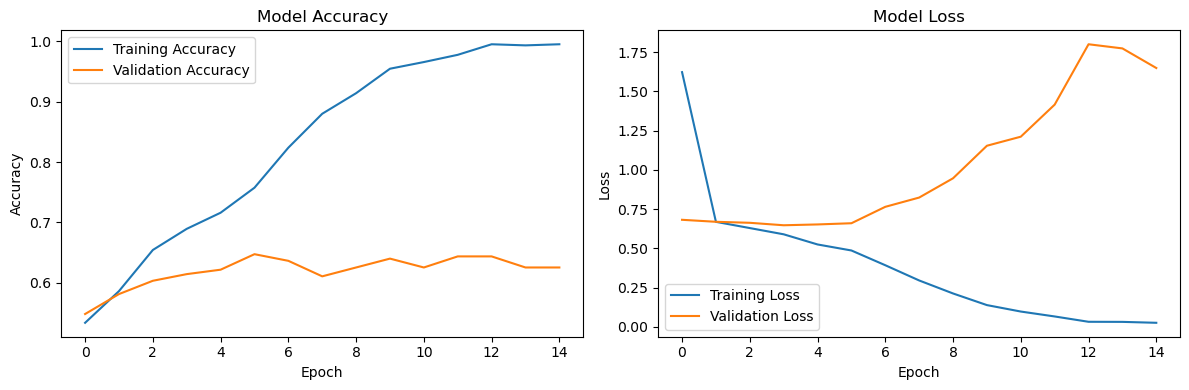

2026-06-25 20:06:20.013302: I external/local_xla/xla/service/gpu/autotuning/conv_algorithm_picker.cc:549] Omitted potentially buggy algorithm eng14{k25=2} for conv %cudnn-conv-bias-activation.9 = (f32[32,32,224,224]{3,2,1,0}, u8[0]{0}) custom-call(f32[32,1,224,224]{3,2,1,0} %bitcast.455, f32[32,1,3,3]{3,2,1,0} %bitcast.462, f32[32]{0} %bitcast.464), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBiasActivationForward", metadata={op_type="Conv2D" op_name="sequential_1_1/conv2d_3_1/convolution" source_file="/home/darren/miniconda3/envs/final_project/lib/python3.9/site-packages/tensorflow/python/framework/ops.py" source_line=1200}, backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"conv_result_scale":1,"activation_mode":"kRelu","side_input_scale":0,"leakyrelu_alpha":0},"force_earliest_schedule":false}
2026-06-25 20:06:20.140333: I external/local_xla/xla/service/gpu/autotuning/conv_algorithm_picke

11/11 - 3s - 266ms/step - accuracy: 0.5912 - loss: 1.8376
Test Accuracy: 0.5912
Test Loss: 1.8376


In [14]:
# plot results after training
import matplotlib.pyplot as plt

# Plot training history
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

# Evaluate on test set
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=2)
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Loss: {test_loss:.4f}")